# 🦅 APT + Reverse Layer-Wise PPF (Reverse L-PPF: α = 0.55 → 0.85) — CUB-200 (Thực nghiệm Phản nghiệm Đối chứng)

## 📌 Bối cảnh & Mục tiêu Nghiên cứu (Negative Control / Sanity Check Ablation)
* **Câu hỏi nghiên cứu**: *"Liệu sự vượt trội của Hierarchical Layer-Wise PPF (L-PPF) có thực sự đến từ hướng phân tầng: Bảo thủ ở tầng nông ($\alpha=0.85$) và Dẻo dai ở tầng sâu ($\alpha=0.55$)? Hay bất kỳ sự phân chia $\alpha$ nào cũng mang lại hiệu quả tương tự?"*
* **Phương pháp kiểm chứng (Reverse L-PPF)**: Ta đảo ngược hoàn toàn hướng của vector $\alpha$:
  * **Tầng nông (Layer 0–3)**: $\alpha$ giảm xuống **0.55** (tăng độ biến động, giảm khả năng giữ tri thức cũ).
  * **Tầng sâu (Layer 8–11)**: $\alpha$ tăng lên **0.85** (tăng độ bảo thủ, hạn chế tiếp thu thông tin mới).
  * **Giá trị trung bình**: Vẫn giữ nguyên tuyệt đối $\bar{\alpha} = \frac{0.55 + 0.85}{2} = 0.70$ (đảm bảo tính công bằng 100% với Uniform PPF $\alpha=0.70$ và Standard L-PPF).
  * **Không tăng tham số**: Vẫn là 0.018M prompt parameters (0 tham số bổ sung).

### 🧠 Dự đoán Lý thuyết (Hypothesis):
1. **Phá hủy biểu diễn gốc ở tầng nông (Low-level Feature Drift)**: Tầng 0–3 biểu diễn các đường nét hình học, góc cạnh thô. Đặt $\alpha=0.55$ khiến trọng số mới chiếm tới $45\%$ mỗi task, làm các bộ lọc thị giác cơ bản bị "xáo trộn" liên tục $\to$ **Tỷ lệ quên ($F_T$) sẽ tăng vọt**.
2. **Cứng nhắc ở tầng ngữ nghĩa sâu (Semantic Rigidity)**: Tầng 8–11 biểu diễn đặc trưng phân biệt chi tiết các loài chim. Đặt $\alpha=0.85$ khiến tầng này bị khóa cứng, chỉ tiếp thu $15\%$ gradient mới $\to$ **Không đủ độ dẻo để học tốt các loài chim mới (tụt $R_{t,t}$)**.
3. **Kết luận kỳ vọng**: Hiệu năng của Reverse L-PPF sẽ **tụt dốc rõ rệt** so với Standard L-PPF ($0.85 \to 0.55$) và thậm chí **kém hơn cả Uniform PPF ($\alpha=0.70$)**. Đây sẽ là minh chứng khoa học đanh thép nhất cho tính đúng đắn của giả thuyết thiết kế L-PPF ban đầu!

---

### 🧪 Giao thức Chia Dữ liệu (Stratified Disjoint 5-Fold)
* Chạy trên kịch bản kiểm định: `phase = "val"` (80% Train / 20% Val) qua 3 seeds `[0, 1, 2]`.
* Khảo sát toàn diện 4 kịch bản task: `task_splits = [5, 10, 20, 40]`.
* Kết quả được lưu tự động theo thời gian thực vào `results.json`.

## 1. Cài đặt Môi trường & Thư viện
* Kích hoạt `line_buffering=True` để Kaggle Console / Viewer hiển thị logs thời gian thực.
* Tự động cài đặt thư viện `timm` nếu môi trường chưa có.
* Cấu hình tối ưu hóa phần cứng PyTorch trên GPU T4.


In [1]:
import os, sys, json, time, math, random, subprocess, warnings
warnings.filterwarnings("ignore")

# Đảm bảo hiển thị log tức thì trên Kaggle Console / Viewer
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(line_buffering=True)

try:
    import timm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
    import timm

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms as T
from PIL import Image

print(f"torch {torch.__version__} | timm {timm.__version__}", flush=True)
assert torch.cuda.is_available(), "⚠️ Chưa bật GPU: Hãy vào Settings → Accelerator → GPU T4 x2"
DEVICE = "cuda"
print(f"✅ GPU đang hoạt động: {torch.cuda.get_device_name(0)}", flush=True)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True


torch 2.11.0+cu128 | timm 1.0.29
✅ GPU đang hoạt động: Tesla T4


## 2. Cấu hình Thực nghiệm (`CFG`)
* `ppf_mode`: `"layer_wise"` với `alpha_range=(0.55, 0.85)` (Đảo ngược: Nông 0.55 -> Sâu 0.85, Mean = 0.70).
* `phase`: Mặc định `"val"` (80% Train / 20% Val) để khảo sát và so sánh trực tiếp.
* `task_splits`: `[5, 10, 20, 40]` (5T: 40 cls, 10T: 20 cls, 20T: 10 cls, 40T: 5 cls).
* `seeds`: `[0, 1, 2]` tương ứng 3 fold Validation không trùng lặp (0% overlap).
* `out_dir`: `"/kaggle/working/outputs_reverse_lppf_val"`.

In [2]:
CFG = dict(
    seeds=[0, 1, 2],           # 3 seed tương ứng 3 fold val độc lập (0% overlap)
    n_classes=200,
    n_tasks=10,                # 10 task x 20 lớp (sẽ cập nhật theo task_splits)
    task_splits=[5, 10, 20, 40], # CUB-200: 5T (40 lớp), 10T (20 lớp), 20T (10 lớp), 40T (5 lớp)
    phase="val",               # 'val': đo đạc chọn model (80% tr/20% va)
    max_tasks=None,            # None: chạy đủ tất cả task; đặt số nguyên (vd: 2) để test nhanh
    epochs=20,                 # APT paper: 18-20 epoch/task cho CUB-200
    batch_size=128,
    prompt_lr=0.02,            # lr của APT cho CUB-200
    head_lr={"linear": 0.02, "kac": 1e-3, "hybrid_cos": 0.02, "hybrid_kac": 1e-3},
    ema_coeff=0.7,             # Hệ số PPF gốc (Mean của 0.55 và 0.85)
    ppf_mode="layer_wise",     # "layer_wise" (với alpha_range đảo ngược)
    alpha_range=(0.55, 0.85),  # (alpha_shallow=0.55, alpha_deep=0.85), Mean = 0.70
    clf_types=["hybrid"],      # APT Reverse L-PPF + Hybrid Classifier
    tau=2.0,                   # Temperature scaling cho Cosine Head
    alpha=1.5,                 # Trọng số kết hợp KAC Head
    kac_num_grids=4,           # KAC paper: 4 knot grids
    kac_grid_range=(-2.0, 2.0),
    use_amp=True,              # Tăng tốc độ với FP16 backbone
    num_workers=2,             # Ổn định nhất cho môi trường Kaggle 2 vCPUs
    max_train_batches=None,    # Debug: giới hạn batch mỗi epoch
    cub_dir="/kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder",
    out_dir="/kaggle/working/outputs_reverse_lppf_val",
    timm_name="vit_base_patch16_224.augreg_in21k_ft_in1k",
)

DEBUG = False   # True: chạy siêu nhanh 2 task x 1 epoch để test code
if DEBUG:
    CFG.update(seeds=[0], max_tasks=2, epochs=1, max_train_batches=3)

os.makedirs(CFG["out_dir"], exist_ok=True)
print(json.dumps(CFG, indent=2), flush=True)

{
  "seeds": [
    0,
    1,
    2
  ],
  "n_classes": 200,
  "n_tasks": 10,
  "task_splits": [
    5,
    10,
    20,
    40
  ],
  "phase": "val",
  "max_tasks": null,
  "epochs": 20,
  "batch_size": 128,
  "prompt_lr": 0.02,
  "head_lr": {
    "linear": 0.02,
    "kac": 0.001,
    "hybrid_cos": 0.02,
    "hybrid_kac": 0.001
  },
  "ema_coeff": 0.7,
  "ppf_mode": "layer_wise",
  "alpha_range": [
    0.55,
    0.85
  ],
  "clf_types": [
    "hybrid"
  ],
  "tau": 2.0,
  "alpha": 1.5,
  "kac_num_grids": 4,
  "kac_grid_range": [
    -2.0,
    2.0
  ],
  "use_amp": true,
  "num_workers": 2,
  "max_train_batches": null,
  "cub_dir": "/kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder",
  "out_dir": "/kaggle/working/outputs_reverse_lppf_val",
  "timm_name": "vit_base_patch16_224.augreg_in21k_ft_in1k"
}


## 3. Dữ liệu CUB-200 & Giao thức Chia Train / Val / Test
1. **`setup_cub200_seed`**: 
   - Đảo thứ tự lớp vào các task theo `seed`.
   - Chia Stratified Disjoint 5-Fold bên trong từng lớp: Fold `seed` làm Val (20%), 4 Fold còn lại làm Train (80%).
2. **`get_task_subsets`**:
   - Ở `phase="val"`: Trích xuất 80% Train của task hiện tại, và 20% Val của tất cả các lớp đã học tới task $t$.
   - Ở `phase="test"`: Trích xuất 100% Train gốc của task hiện tại, và Test của tất cả các lớp đã học tới task $t$.
3. **`RemapTransformDataset`**: Bọc `Subset` để ánh xạ nhãn gốc (0..199) sang nhãn lớp tuần tự $[t \cdot \text{per}, (t+1) \cdot \text{per})$ phù hợp với cấu trúc phân loại của Continual Learning, đồng thời áp dụng `TRAIN_TF` hoặc `TEST_TF`.


In [3]:
# 1. Tự động nhận diện đường dẫn CUB-200-2011 trên Kaggle
CUB_CANDIDATES = [
    CFG["cub_dir"],
    "/kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder",
    "/kaggle/input/cub-200-2011-by-classes-folder",
]
CUB_ROOT = next((p for p in CUB_CANDIDATES if os.path.isdir(os.path.join(p, "train")) and os.path.isdir(os.path.join(p, "test"))), CUB_CANDIDATES[0])

# 2. Hàm chuẩn Phương án A: vừa đảo thứ tự Task theo seed, vừa lấy Fold[seed] làm Val (0% overlap)
def setup_cub200_seed(train_dataset, seed, num_classes=200, task_sizes=None, n_splits=5, base_seed=1993):
    assert 0 <= seed < n_splits, f"seed phải nằm trong [0, {n_splits-1}]"
    if task_sizes is None:
        task_sizes = [20] * 10  # 10 tasks x 20 classes = 200 classes

    # (a) Đảo thứ tự class vào 10 Tasks theo seed
    rng_task = np.random.RandomState(seed)
    class_order = rng_task.permutation(num_classes).tolist()
    task_classes, cur = [], 0
    for sz in task_sizes:
        task_classes.append(class_order[cur : cur + sz])
        cur += sz

    # (b) Chia Stratified Disjoint 5-Fold bên trong từng class -> lấy Fold[seed] làm Val (20%)
    targets = np.asarray(train_dataset.targets)
    tr_idx, va_idx = [], []
    rng_split = np.random.RandomState(base_seed)
    for c in range(num_classes):
        c_indices = np.where(targets == c)[0]
        perm = rng_split.permutation(c_indices)
        folds = np.array_split(perm, n_splits)
        va_idx.extend(folds[seed])
        for k in range(n_splits):
            if k != seed:
                tr_idx.extend(folds[k])

    return task_classes, np.array(tr_idx), np.array(va_idx)

def get_task_subsets(train_dataset, test_dataset, task_classes, tr_idx, va_idx, task_id, phase="val"):
    """
    Lấy Subset tại Task `task_id` (0..9):
      - phase="val"  (Giai đoạn 1 - Baseline / Improve): học trên 80% Train, đánh giá trên 20% Val (KHÔNG đụng Test).
      - phase="test" (Giai đoạn 2 - Chốt số cuối cùng) : học trên 100% Train gốc, đánh giá trên Test chính thức.
    """
    cur_cls = set(task_classes[task_id])
    seen_cls = set(sum(task_classes[: task_id + 1], []))
    tr_targets = np.asarray(train_dataset.targets)

    if phase == "val":
        t_tr_idx = [i for i in tr_idx if tr_targets[i] in cur_cls]
        t_ev_idx = [i for i in va_idx if tr_targets[i] in seen_cls]
        return Subset(train_dataset, t_tr_idx), Subset(train_dataset, t_ev_idx)
    elif phase == "test":
        te_targets = np.asarray(test_dataset.targets)
        t_tr_idx = [i for i in range(len(tr_targets)) if tr_targets[i] in cur_cls]
        t_ev_idx = [i for i in range(len(te_targets)) if te_targets[i] in seen_cls]
        return Subset(train_dataset, t_tr_idx), Subset(test_dataset, t_ev_idx)
    else:
        raise ValueError("phase phải là 'val' hoặc 'test'")

# 3. Data Transformations chuẩn APT / CODA-Prompt
TRAIN_TF = T.Compose([
    T.AutoAugment(T.AutoAugmentPolicy.IMAGENET, T.InterpolationMode.BILINEAR),
    T.RandomResizedCrop(224),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
])
TEST_TF = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
])

class RemapTransformDataset(Dataset):
    """Bọc Subset từ ImageFolder để re-map nhãn lớp sang contiguous order và áp dụng Transform tương ứng."""
    def __init__(self, subset, transform, remap):
        self.subset = subset
        self.transform = transform
        self.remap = remap

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, y = self.subset[idx]
        if self.transform is not None:
            img = self.transform(img)
        new_y = self.remap[y] if self.remap is not None else y
        return img, new_y

# 4. Khởi tạo ImageFolder (transform=None để Dataset Wrapper tự áp dụng phù hợp cho train/val)
cub_train = ImageFolder(os.path.join(CUB_ROOT, "train"))
cub_test  = ImageFolder(os.path.join(CUB_ROOT, "test"))

print("=" * 100, flush=True)
print(f"✅ [CUB-200-2011] Đọc từ: {CUB_ROOT}", flush=True)
print(f"   Số lớp: {len(cub_train.classes)} | Train gốc: {len(cub_train)} ảnh | Test gốc: {len(cub_test)} ảnh", flush=True)
print(f"   Chế độ hiện tại (Phase): {CFG['phase'].upper()}", flush=True)
print("-" * 100, flush=True)

val_sets, seed_rows = {}, []
for s in CFG["seeds"]:
    t_cls, tr_i, va_i = setup_cub200_seed(cub_train, seed=s)
    val_sets[s] = set(va_i.tolist())
    va_per_cls = pd.Series(np.asarray(cub_train.targets)[va_i]).value_counts()
    seed_rows.append({
        "Seed": s,
        "Train 80% (Improve)": len(tr_i),
        "Val 20% (Improve)": len(va_i),
        "Min Val/lớp": int(va_per_cls.min()),
        "Max Val/lớp": int(va_per_cls.max()),
        "Train 100% (Chốt)": len(cub_train),
        "Test (Chốt)": len(cub_test),
        "Task 1 (5 lớp đầu)": t_cls[0][:5]
    })

print(pd.DataFrame(seed_rows).to_string(index=False), flush=True)
if len(CFG["seeds"]) >= 3:
    ov01 = len(val_sets[0] & val_sets[1])
    ov12 = len(val_sets[1] & val_sets[2])
    ov02 = len(val_sets[0] & val_sets[2])
    print(f"👉 Xác nhận Val không trùng: Overlap(0,1)={ov01} | Overlap(1,2)={ov12} | Overlap(0,2)={ov02}", flush=True)
print("=" * 100, flush=True)


✅ [CUB-200-2011] Đọc từ: /kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder
   Số lớp: 200 | Train gốc: 5994 ảnh | Test gốc: 5794 ảnh
   Chế độ hiện tại (Phase): VAL
----------------------------------------------------------------------------------------------------
 Seed  Train 80% (Improve)  Val 20% (Improve)  Min Val/lớp  Max Val/lớp  Train 100% (Chốt)  Test (Chốt)       Task 1 (5 lớp đầu)
    0                 4794               1200            6            6               5994         5794  [18, 170, 107, 98, 177]
    1                 4794               1200            6            6               5994         5794   [58, 40, 34, 102, 184]
    2                 4794               1200            6            6               5994         5794 [112, 29, 182, 199, 193]
👉 Xác nhận Val không trùng: Overlap(0,1)=0 | Overlap(1,2)=0 | Overlap(0,2)=0


## 4. Kiến trúc Mô hình: ViT-B/16 + APT Prompt (L-PPF) + Hybrid Classifier
* **Backbone**: ViT-B/16 (đóng băng trọng số).
* **Additive Prompt (APT)**: 24 prompt tokens ($12 \text{ layers} \times 2$ cho Key & Value cộng vào token `[CLS]`).
* **Hierarchical Layer-Wise PPF (L-PPF)**:
  * Khởi tạo vector trọng số $\alpha_l$ biến thiên tuyến tính từ $0.85$ (Layer 0) xuống $0.55$ (Layer 11).
  * Công thức merge: $\mathcal{P}_{\text{merged}}^{(l)} = \alpha_l \cdot \mathcal{P}_{\text{merged}}^{(l)} + (1 - \alpha_l) \cdot \mathcal{P}_{t}^{(l)}$.
* **Hybrid Classifier Head**:
  * **Cosine Head**: LayerNorm không affine + L2-normalized linear classifier.
  * **KAC Head**: LayerNorm + Gaussian RBF kernel basis + Spline linear.
  * Tích hợp suy luận: $P = \text{softmax}(z_{cos} / \tau) + \alpha \cdot \text{softmax}(z_{kac})$.
  * Huấn luyện: $\mathcal{L} = \mathcal{L}_{CE}(z_{cos}) + \mathcal{L}_{CE}(z_{kac})$.


In [4]:
# ---------------- ViT-B/16 (frozen) có hook cho Additive Prompt ----------------
class PatchEmbed(nn.Module):
    def __init__(self, dim=768, patch=16):
        super().__init__()
        self.proj = nn.Conv2d(3, dim, patch, patch)
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)

class Attention(nn.Module):
    def __init__(self, dim=768, heads=12):
        super().__init__()
        self.heads, self.hd = heads, dim // heads
        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.proj = nn.Linear(dim, dim)
    def forward(self, x, prompt=None):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.heads, self.hd).permute(2, 0, 3, 1, 4).unbind(0)
        if prompt is not None:
            # APT: cộng prompt vào key/value của CLS token (vị trí 0), patch token giữ nguyên
            pk, pv = prompt                                   # (H, 1, hd)
            k = torch.cat([k[:, :, :1] + pk.to(k.dtype), k[:, :, 1:]], dim=2)
            v = torch.cat([v[:, :, :1] + pv.to(v.dtype), v[:, :, 1:]], dim=2)
        x = F.scaled_dot_product_attention(q, k, v)
        return self.proj(x.transpose(1, 2).reshape(B, N, C))

class Mlp(nn.Module):
    def __init__(self, dim=768, hidden=3072):
        super().__init__()
        self.fc1, self.act, self.fc2 = nn.Linear(dim, hidden), nn.GELU(), nn.Linear(hidden, dim)
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

class Block(nn.Module):
    def __init__(self, dim=768, heads=12):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = Attention(dim, heads)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim, dim * 4)
    def forward(self, x, prompt=None):
        x = x + self.attn(self.norm1(x), prompt)
        return x + self.mlp(self.norm2(x))

class ViT(nn.Module):
    def __init__(self, dim=768, depth=12, heads=12):
        super().__init__()
        self.depth, self.heads = depth, heads
        self.patch_embed = PatchEmbed(dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 197, dim))
        self.blocks = nn.ModuleList([Block(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim, eps=1e-6)
    def forward(self, x, prompt_fn=None):
        x = self.patch_embed(x)
        x = torch.cat([self.cls_token.expand(x.shape[0], -1, -1), x], dim=1) + self.pos_embed
        for i, blk in enumerate(self.blocks):
            x = blk(x, prompt_fn(i) if prompt_fn is not None else None)
        return self.norm(x)[:, 0]          # CLS feature

def load_pretrained_vit(name):
    try:
        ref = timm.create_model(name, pretrained=True, num_classes=0)
    except Exception as e:
        print(f"[warn] không tải được {name} ({e}); thử 'vit_base_patch16_224'", flush=True)
        ref = timm.create_model("vit_base_patch16_224", pretrained=True, num_classes=0)
    sd = {k: v for k, v in ref.state_dict().items() if not k.startswith("head")}
    vit = ViT()
    missing, unexpected = vit.load_state_dict(sd, strict=False)
    assert not missing, f"Thiếu key: {missing}"
    if unexpected:
        print("[info] bỏ qua key:", unexpected, flush=True)
    for p in vit.parameters():
        p.requires_grad_(False)
    return vit.eval(), ref.eval()

# ---------------- APTPrompt với Hierarchical Layer-Wise PPF (L-PPF) ----------------
class APTPrompt(nn.Module):
    """
    APTPrompt với cơ chế Hierarchical Layer-Wise PPF (L-PPF):
    - Tầng nông (Layer 0-3): alpha cao (0.85) để bảo toàn đặc trưng hình học tổng quát (chống quên).
    - Tầng sâu (Layer 8-11): alpha thấp hơn (0.55) để tăng độ dẻo thích nghi với các loài chim mới.
    - Giữ nguyên cấu trúc 24 prompt vectors của APT gốc (0 tham số bổ sung).
    """
    def __init__(self, depth=12, dim=768, heads=12, ema_coeff=0.7, 
                 ppf_mode="layer_wise", alpha_range=(0.85, 0.55)):
        super().__init__()
        self.depth, self.heads, self.hd = depth, heads, dim // heads
        self.ppf_mode = ppf_mode
        self.alpha_range = alpha_range
        self.ema_coeff = ema_coeff
        
        # 12 tầng * 2 prompts [k_0, v_0, k_1, v_1, ...] = 24 vectors (dim=768)
        self.prompt_tokens = nn.Parameter(torch.zeros(depth * 2, dim))
        nn.init.trunc_normal_(self.prompt_tokens, std=0.02)
        self.register_buffer("merged", torch.zeros(depth * 2, dim))
        self.n_merged = 0
        self.use_merged = False
        
        # Tạo vector trọng số alpha cho từng vector prompt
        if ppf_mode == "layer_wise":
            a_shallow, a_deep = alpha_range
            alphas = torch.linspace(a_shallow, a_deep, depth) # (12,)
            # Nhân đôi cho 2 vector (k và v) của mỗi tầng: shape (24, 1)
            alphas_24 = alphas.repeat_interleave(2).unsqueeze(1)
            self.register_buffer("layer_alphas", alphas_24)
        else:
            self.register_buffer("layer_alphas", torch.full((depth * 2, 1), ema_coeff))
            
    def get(self, l):
        P = self.merged if self.use_merged else self.prompt_tokens
        return P[2 * l].view(self.heads, 1, self.hd), P[2 * l + 1].view(self.heads, 1, self.hd)
        
    @torch.no_grad()
    def merge(self):
        # Sau mỗi task: task 1 copy, các task sau: merged = a_l * merged + (1 - a_l) * current
        if self.n_merged == 0:
            self.merged.copy_(self.prompt_tokens)
        else:
            a = self.layer_alphas
            self.merged.copy_(self.merged * a + self.prompt_tokens * (1.0 - a))
        self.n_merged += 1
        
        # In chẩn đoán PPF merge
        a_0 = self.layer_alphas[0].item()
        a_last = self.layer_alphas[-1].item()
        a_mean = self.layer_alphas.mean().item()
        print(f"  [Reverse L-PPF Merge #{self.n_merged}] Layer 0 (Shallow) α={a_0:.3f} -> Layer 11 (Deep) α={a_last:.3f} (Mean={a_mean:.3f})", flush=True)

# ---------------- Classifier heads ----------------
class CosineHead(nn.Module):
    """Head gốc của APT: LayerNorm (không affine) + linear với weight chuẩn hoá L2, không bias."""
    def __init__(self, dim, n_cls):
        super().__init__()
        self.norm = nn.LayerNorm(dim, elementwise_affine=False)
        self.fc = nn.Linear(dim, n_cls, bias=False)
    def forward(self, f):
        return self.norm(f) @ F.normalize(self.fc.weight, dim=1).t()

class KACHead(nn.Module):
    """KAC (Hu et al., CVPR 2025): LayerNorm -> Gaussian RBF basis -> spline linear."""
    def __init__(self, dim, n_cls, num_grids=4, grid_range=(-2.0, 2.0)):
        super().__init__()
        gmin, gmax = grid_range
        self.layernorm = nn.LayerNorm(dim)
        self.register_buffer("grid", torch.linspace(gmin, gmax, num_grids))
        self.denominator = (gmax - gmin) / (num_grids - 1)
        self.spline_linear = nn.Linear(dim * num_grids, n_cls, bias=False)
        nn.init.zeros_(self.spline_linear.weight)
    def forward(self, f):
        x = self.layernorm(f)
        basis = torch.exp(-((x[..., None] - self.grid) / self.denominator) ** 2)   # (B, d, G)
        return self.spline_linear(basis.flatten(1))

class HybridHead(nn.Module):
    def __init__(self, dim, n_cls, num_grids=4, grid_range=(-2.0, 2.0), tau=2.0, alpha=1.5):
        super().__init__()
        self.cos_head = CosineHead(dim, n_cls)
        self.kac_head = KACHead(dim, n_cls, num_grids, grid_range)
        self.tau = tau
        self.alpha = alpha
    def forward(self, f):
        out_norm = self.cos_head.norm(f)
        logit_cos = self.cos_head(f)
        logit_kac = self.kac_head(f.detach())
        if self.training:
            return logit_cos, logit_kac
        else:
            return logit_cos, logit_kac, out_norm

class APTNet(nn.Module):
    def __init__(self, vit, n_cls, clf_type, cfg):
        super().__init__()
        self.vit = vit
        self.prompt = APTPrompt(
            vit.depth, 768, vit.heads,
            ema_coeff=cfg["ema_coeff"],
            ppf_mode=cfg.get("ppf_mode", "layer_wise"),
            alpha_range=cfg.get("alpha_range", (0.85, 0.55))
        )
        if clf_type == "linear":
            self.head = CosineHead(768, n_cls)
        elif clf_type == "kac":
            self.head = KACHead(768, n_cls, cfg["kac_num_grids"], cfg["kac_grid_range"])
        elif clf_type == "hybrid":
            self.head = HybridHead(768, n_cls, cfg["kac_num_grids"], cfg["kac_grid_range"], cfg["tau"], cfg["alpha"])
        else:
            raise ValueError(clf_type)
        self.use_amp = cfg["use_amp"]
    def forward(self, x):
        self.prompt.use_merged = (not self.training) and self.prompt.n_merged > 0
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp):
            f = self.vit(x, prompt_fn=self.prompt.get)
        with torch.autocast("cuda", enabled=False):
            return self.head(f.float())


Tải ViT-B/16 pretrained và kiểm tra khớp timm.


In [5]:
VIT, REF = load_pretrained_vit(CFG["timm_name"])
VIT, REF = VIT.to(DEVICE), REF.to(DEVICE)

# Sanity check: ViT tự viết (không prompt) phải khớp timm (tắt TF32 khi so sánh)
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
with torch.no_grad():
    x = torch.rand(2, 3, 224, 224, device=DEVICE)
    ref = REF.forward_features(x)[:, 0]
    rel = ((VIT(x) - ref).abs().max() / ref.abs().max()).item()
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
print(f"✅ relative max diff với timm = {rel:.2e}", flush=True)
assert rel < 1e-3, "ViT tự viết không khớp timm!"
del REF; torch.cuda.empty_cache()


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

✅ relative max diff với timm = 0.00e+00


## 5. Quy trình Huấn luyện & Đánh giá Class-Incremental
* **Class Remapping**: Tự động ánh xạ nhãn các lớp của mỗi task thành block tuần tự $[t \cdot \text{per}, (t+1) \cdot \text{per})$.
* **Evaluate**: Đánh giá trên tất cả các lớp đã thấy tới task $t$. Khi đến task cuối cùng, tự động thực hiện **Offline Grid Search** trên logits tập Validation để tìm siêu tham số $\tau^*, \alpha^*$ tối ưu mà hoàn toàn không đụng đến Test set.


In [6]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)

@torch.no_grad()
def evaluate(model, eval_loader, n_seen_tasks, per, clf_type='hybrid', tau=2.0, alpha=1.5):
    hi = n_seen_tasks * per
    model.eval()
    all_logit_cos, all_logit_kac, all_f_norm, ys = [], [], [], []
    all_logits = []
    
    for x, y in eval_loader:
        out = model(x.to(DEVICE, non_blocking=True))
        if clf_type == "hybrid":
            logit_cos, logit_kac, f_norm = out
            all_logit_cos.append(logit_cos.cpu())
            all_logit_kac.append(logit_kac.cpu())
            all_f_norm.append(f_norm.cpu())
        else:
            all_logits.append(out.cpu())
        ys.append(y)
        
    y = torch.cat(ys)
    task_of = y // per
    
    if clf_type == "hybrid":
        logit_cos = torch.cat(all_logit_cos)[:, :hi]
        logit_kac = torch.cat(all_logit_kac)[:, :hi]
        f_norm = torch.cat(all_f_norm)
        
        # 1. Effective Rank của features sau Cosine LayerNorm
        _, S, _ = torch.linalg.svd(f_norm.float(), full_matrices=False)
        S = S / S.sum()
        entropy = - (S * torch.log(S + 1e-9)).sum()
        eff_rank = torch.exp(entropy).item()
        
        # 2. Out of Grid (%)
        u_out_of_grid = ((f_norm < -2.0) | (f_norm > 2.0)).float().mean().item() * 100
        
        # 3. Task-Aware Accuracy (Upper Bound tham chiếu)
        correct_ta = 0
        for j in range(n_seen_tasks):
            lo, hi_task = j * per, (j + 1) * per
            mask = (task_of == j)
            if mask.sum() > 0:
                prob_cos = F.softmax(logit_cos[mask][:, lo:hi_task] / tau, dim=1)
                prob_kac = F.softmax(logit_kac[mask][:, lo:hi_task], dim=1)
                pred_ta = (prob_cos + alpha * prob_kac).argmax(dim=1) + lo
                correct_ta += (pred_ta == y[mask]).sum().item()
        acc_ta = 100.0 * correct_ta / max(len(y), 1)
        
        # 4. Standard CIL Accuracy (Tích hợp Cosine + KAC)
        prob_cos = F.softmax(logit_cos / tau, dim=1)
        prob_kac = F.softmax(logit_kac, dim=1)
        p = (prob_cos + alpha * prob_kac).argmax(dim=1)
        
        diag = {"eff_rank": eff_rank, "u_out_of_grid": u_out_of_grid, "acc_ta": acc_ta}
        
        # Offline Grid Search tại task cuối cùng để tìm tau, alpha tối ưu trên tập Validation
        if n_seen_tasks == CFG["n_tasks"]:
            print(f"\n[OFFLINE GRID SEARCH - {CFG['phase'].upper()}] Quét siêu tham số tau & alpha tối ưu...", flush=True)
            best_acc, best_tau, best_alpha = 0.0, tau, alpha
            for search_tau in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 8.0, 10.0]:
                for search_alpha in [0.1, 0.5, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5, 3.0]:
                    p_c = F.softmax(logit_cos / search_tau, dim=1)
                    p_k = F.softmax(logit_kac, dim=1)
                    pred = (p_c + search_alpha * p_k).argmax(dim=1)
                    acc = 100.0 * (pred == y).float().mean().item()
                    if acc > best_acc:
                        best_acc, best_tau, best_alpha = acc, search_tau, search_alpha
            print(f"🎯 Kết quả tối ưu nhất trên {CFG['phase']}: tau={best_tau}, alpha={best_alpha} => Accuracy: {best_acc:.2f}%\n", flush=True)
            diag["best_grid_tau"] = best_tau
            diag["best_grid_alpha"] = best_alpha
            diag["best_grid_acc"] = best_acc
    else:
        logits = torch.cat(all_logits)[:, :hi]
        p = logits.argmax(dim=1)
        correct_ta = 0
        for j in range(n_seen_tasks):
            lo, hi_task = j * per, (j + 1) * per
            mask = (task_of == j)
            if mask.sum() > 0:
                pred_ta = logits[mask][:, lo:hi_task].argmax(dim=1) + lo
                correct_ta += (pred_ta == y[mask]).sum().item()
        acc_ta = 100.0 * correct_ta / max(len(y), 1)
        diag = {"eff_rank": 0.0, "u_out_of_grid": 0.0, "acc_ta": acc_ta}

    accs = [100.0 * (p[task_of == j] == y[task_of == j]).float().mean().item() for j in range(n_seen_tasks)]
    overall = 100.0 * (p == y).float().mean().item()

    return accs, overall, diag

def summarize(R):
    Tn = R.shape[0]
    A = [float(np.mean(R[t, :t + 1])) for t in range(Tn)]
    fgt = float(np.mean([R[j, j] - R[Tn - 1, j] for j in range(Tn - 1)])) if Tn > 1 else 0.0
    return dict(A_t=A, last=A[-1], avg=float(np.mean(A)), forgetting=fgt)

def run_experiment(seed, clf_type):
    set_seed(seed)
    C, nT = CFG["n_classes"], CFG["n_tasks"]
    per = C // nT
    task_sizes = [per] * nT

    # 1. Phân chia Train/Val 5-Fold theo seed
    task_classes, tr_idx, va_idx = setup_cub200_seed(
        cub_train, seed=seed, num_classes=C, task_sizes=task_sizes, n_splits=5, base_seed=1993
    )
    class_order = sum(task_classes, [])
    remap = {c: i for i, c in enumerate(class_order)}
    Tn = nT if CFG["max_tasks"] is None else min(nT, CFG["max_tasks"])

    model = APTNet(VIT, C, clf_type, CFG).to(DEVICE)
    n_train = sum(p.numel() for p in [model.prompt.prompt_tokens, *model.head.parameters()])
    print(f"\n{'#'*70}", flush=True)
    print(f"### {clf_type.upper()} + L-PPF ({CFG['ppf_mode']}) | Seed: {seed} | Phase: {CFG['phase'].upper()} | Trainable params: {n_train/1e6:.3f}M", flush=True)
    print(f"{'#'*70}", flush=True)

    R = np.zeros((Tn, Tn))
    log = []
    for t in range(Tn):
        lo, hi = t * per, (t + 1) * per
        raw_tr, raw_ev = get_task_subsets(
            cub_train, cub_test, task_classes, tr_idx, va_idx, task_id=t, phase=CFG["phase"]
        )
        train_ds = RemapTransformDataset(raw_tr, TRAIN_TF, remap)
        eval_ds  = RemapTransformDataset(raw_ev, TEST_TF, remap)

        train_loader = DataLoader(
            train_ds, batch_size=CFG["batch_size"], shuffle=True,
            drop_last=(len(train_ds) > CFG["batch_size"]),
            num_workers=CFG["num_workers"], pin_memory=True
        )
        eval_loader = DataLoader(
            eval_ds, batch_size=128, shuffle=False,
            num_workers=CFG["num_workers"], pin_memory=True
        )

        if clf_type == "hybrid":
            opt = torch.optim.Adam([
                {"params": [model.prompt.prompt_tokens], "lr": CFG["prompt_lr"]},
                {"params": list(model.head.cos_head.parameters()), "lr": CFG["head_lr"]["hybrid_cos"]},
                {"params": list(model.head.kac_head.parameters()), "lr": CFG["head_lr"]["hybrid_kac"]},
            ], betas=(0.9, 0.999), weight_decay=0.0)
        else:
            opt = torch.optim.Adam([
                {"params": [model.prompt.prompt_tokens], "lr": CFG["prompt_lr"]},
                {"params": list(model.head.parameters()), "lr": CFG["head_lr"][clf_type]},
            ], betas=(0.9, 0.999), weight_decay=0.0)

        base_lrs = [g["lr"] for g in opt.param_groups]
        scaler = make_scaler(CFG["use_amp"])
        E = CFG["epochs"]
        t0 = time.time()
        grads_this_task = []

        for ep in range(E):
            fac = math.cos(99 * math.pi * ep / (200 * max(E - 1, 1)))
            for g, b in zip(opt.param_groups, base_lrs):
                g["lr"] = b * fac
            model.train()
            tot, correct, n = 0.0, 0, 0
            ep_p_grad, ep_c_grad, steps = 0.0, 0.0, 0

            for bi, (x, y) in enumerate(train_loader):
                if CFG["max_train_batches"] and bi >= CFG["max_train_batches"]:
                    break
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                out = model(x)
                if clf_type == "hybrid":
                    logits_cos = out[0][:, lo:hi]
                    logits_kac = out[1][:, lo:hi]
                    loss = F.cross_entropy(logits_cos, y - lo) + F.cross_entropy(logits_kac, y - lo)
                    logits = logits_cos
                else:
                    logits = out[:, lo:hi]
                    loss = F.cross_entropy(logits, y - lo)

                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()

                # Gradient tracking
                scaler.unscale_(opt)
                with torch.no_grad():
                    if hasattr(model.prompt, 'prompt_tokens') and model.prompt.prompt_tokens.grad is not None:
                        ep_p_grad += model.prompt.prompt_tokens.grad.norm().item()
                    c_grad = 0.0
                    for p in model.head.parameters():
                        if p.grad is not None:
                            c_grad += p.grad.norm().item()
                    ep_c_grad += c_grad
                steps += 1

                scaler.step(opt)
                scaler.update()
                tot += loss.item() * len(y); n += len(y)
                correct += (logits.argmax(1) == (y - lo)).sum().item()

            if steps > 0:
                grads_this_task.append({
                    "step": ep + 1,
                    "p_grad": round(ep_p_grad / steps, 4),
                    "c_grad": round(ep_c_grad / steps, 4)
                })

            if ep == 0 or ep == E - 1 or (ep + 1) % 5 == 0:
                print(f"  task {t+1:2d} ep {ep+1:2d}/{E} | loss {tot/max(n,1):.3f} | train acc {100*correct/max(n,1):.1f}%", flush=True)

        model.prompt.merge()
        accs, overall, diag = evaluate(model, eval_loader, t + 1, per, clf_type=clf_type, tau=CFG["tau"], alpha=CFG["alpha"])
        R[t, :t + 1] = accs
        A_t = float(np.mean(accs))
        log.append(dict(task=t + 1, A_t=A_t, sample_acc=overall, train_time=time.time() - t0, accs=accs, grads=grads_this_task, diag=diag))
        print(f"👉 Sau task {t+1:2d}: A_t = {A_t:.2f}% | acc_ta = {diag['acc_ta']:.2f}% | rank = {diag['eff_rank']:.1f} | time = {time.time()-t0:.1f}s", flush=True)

    res = summarize(R)
    formatted_metrics = {str(i_t): {"accs": l_data["accs"], "grads": l_data["grads"]} for i_t, l_data in enumerate(log)}
    res.update(
        R=R.tolist(), log=log, class_order=class_order, seed=seed, clf_type=clf_type, 
        phase=CFG["phase"], ppf_mode=CFG["ppf_mode"], alpha_range=list(CFG["alpha_range"]),
        formatted_metrics=formatted_metrics
    )

    print(f"\n{'='*70}", flush=True)
    print(f"🏆 Reverse L-PPF + {clf_type.upper()} [Seed {seed} | Phase: {CFG['phase']}]: Last {res['last']:.2f}% | Avg {res['avg']:.2f}% | Forgetting {res['forgetting']:.2f}%", flush=True)
    print(f"{'='*70}\n", flush=True)

    torch.save({
        "prompt_tokens": model.prompt.prompt_tokens.detach().cpu(),
        "merged": model.prompt.merged.cpu(),
        "layer_alphas": model.prompt.layer_alphas.cpu(),
        "head": {k: v.cpu() for k, v in model.head.state_dict().items()},
        "class_order": class_order,
        "phase": CFG["phase"],
        "ppf_mode": CFG["ppf_mode"],
        "alpha_range": CFG["alpha_range"]
    }, os.path.join(CFG["out_dir"], f"apt_reverse_lppf_{clf_type}_{CFG['phase']}_seed{seed}.pt"))

    del model, opt; torch.cuda.empty_cache()
    return res


## 6. Chạy Thực nghiệm
* Chạy theo danh sách `seeds` và `task_splits` đã cấu hình.
* Tự động lưu tiến độ vào `results.json` sau mỗi kịch bản.


In [7]:
RESULTS_PATH = os.path.join(CFG["out_dir"], "results.json")
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) and not DEBUG else {}

task_splits = CFG.get("task_splits", [5, 10, 20, 40])
for n_tasks in task_splits:
    CFG["n_tasks"] = n_tasks
    c_per_t = CFG["n_classes"] // n_tasks
    for seed in CFG["seeds"]:
        for clf in CFG["clf_types"]:
            ppf_tag = "RevLPPF"
            key = f"APT_{ppf_tag}_{clf}_{n_tasks}T_{c_per_t}C_{CFG['phase']}_seed{seed}"
            if key in RESULTS:
                print(f"Bỏ qua (đã có kết quả): {key}", flush=True)
                continue
            print(f"\n{'='*60}\n🚀 BẮT ĐẦU: {key} \n{'='*60}", flush=True)
            RESULTS[key] = run_experiment(seed, clf)
            json.dump(RESULTS, open(RESULTS_PATH, "w"), indent=2)
            print(f"💾 Đã lưu kết quả tại: {RESULTS_PATH}", flush=True)


🚀 BẮT ĐẦU: APT_RevLPPF_hybrid_5T_40C_val_seed0 

######################################################################
### HYBRID + L-PPF (layer_wise) | Seed: 0 | Phase: VAL | Trainable params: 0.788M
######################################################################
  task  1 ep  1/20 | loss 4.908 | train acc 58.5%
  task  1 ep  5/20 | loss 1.182 | train acc 90.7%
  task  1 ep 10/20 | loss 0.745 | train acc 93.2%
  task  1 ep 15/20 | loss 0.558 | train acc 95.8%
  task  1 ep 20/20 | loss 0.520 | train acc 96.1%
  [Reverse L-PPF Merge #1] Layer 0 (Shallow) α=0.550 -> Layer 11 (Deep) α=0.850 (Mean=0.700)
👉 Sau task  1: A_t = 94.58% | acc_ta = 94.58% | rank = 184.9 | time = 196.9s
  task  2 ep  1/20 | loss 4.553 | train acc 67.2%
  task  2 ep  5/20 | loss 0.852 | train acc 93.3%
  task  2 ep 10/20 | loss 0.640 | train acc 93.8%
  task  2 ep 15/20 | loss 0.457 | train acc 95.9%
  task  2 ep 20/20 | loss 0.428 | train acc 95.5%
  [Reverse L-PPF Merge #2] Layer 0 (Shallow) α=0.550 -> 

## 7. Tổng hợp Kết quả & Trực quan hóa
* Hiển thị bảng tổng hợp chi tiết theo từng seed và trung bình cộng (Mean $\pm$ Std).
* Vẽ đồ thị Accuracy $A_t$ và ma trận chuyển giao/quên $R[t, j]$.


,Experiment,Method,PPF Mode,Phase,Tasks,Seed,Last Acc (%),Avg Acc (%),Forgetting (%)
0,APT_RevLPPF_hybrid_5T_40C_val_seed0,APT + Reverse L-PPF (Hybrid),layer_wise,val,5,0,85.17,89.74,7.29
1,APT_RevLPPF_hybrid_5T_40C_val_seed1,APT + Reverse L-PPF (Hybrid),layer_wise,val,5,1,84.25,89.63,7.50
2,APT_RevLPPF_hybrid_5T_40C_val_seed2,APT + Reverse L-PPF (Hybrid),layer_wise,val,5,2,84.42,88.60,7.60
3,APT_RevLPPF_hybrid_10T_20C_val_seed0,APT + Reverse L-PPF (Hybrid),layer_wise,val,10,0,80.92,87.60,10.00
4,APT_RevLPPF_hybrid_10T_20C_val_seed1,APT + Reverse L-PPF (Hybrid),layer_wise,val,10,1,80.42,87.25,10.56
5,APT_RevLPPF_hybrid_10T_20C_val_seed2,APT + Reverse L-PPF (Hybrid),layer_wise,val,10,2,82.00,87.40,8.70
6,APT_RevLPPF_hybrid_20T_10C_val_seed0,APT + Reverse L-PPF (Hybrid),layer_wise,val,20,0,75.25,84.59,12.19
7,APT_RevLPPF_hybrid_20T_10C_val_seed1,APT + Reverse L-PPF (Hybrid),layer_wise,val,20,1,73.92,83.38,12.37
8,APT_RevLPPF_hybrid_20T_10C_val_seed2,APT + Reverse L-PPF (Hybrid),layer_wise,val,20,2,75.42,85.22,13.07
9,APT_RevLPPF_hybrid_40T_5C_val_seed0,APT + Reverse L-PPF (Hybrid),layer_wise,val,40,0,70.42,82.10,16.50



📊 THỐNG KÊ TRUNG BÌNH QUA CÁC SEED:


Last Acc (%)        \
                                                            mean   std   
Method                       PPF Mode   Phase Tasks                      
APT + Reverse L-PPF (Hybrid) layer_wise val   5            84.61  0.49   
                                              10           81.11  0.81   
                                              20           74.86  0.82   
                                              40           71.17  0.75   

                                                    Avg Acc (%)        \
                                                           mean   std   
Method                       PPF Mode   Phase Tasks                     
APT + Reverse L-PPF (Hybrid) layer_wise val   5           89.32  0.63   
                                              10          87.42  0.18   
                                              20          84.40  0.94   
                                              40          82.26  0.35   

                                                    Forgetting (%)        
                                                              mean   std  
Method                       PPF Mode   Phase Tasks                       
APT + Reverse L-PPF (Hybrid) layer_wise val   5               7.46  0.16  
                                              10              9.75  0.95  
                                              20             12.54  0.46  
                                              40             15.67  0.72

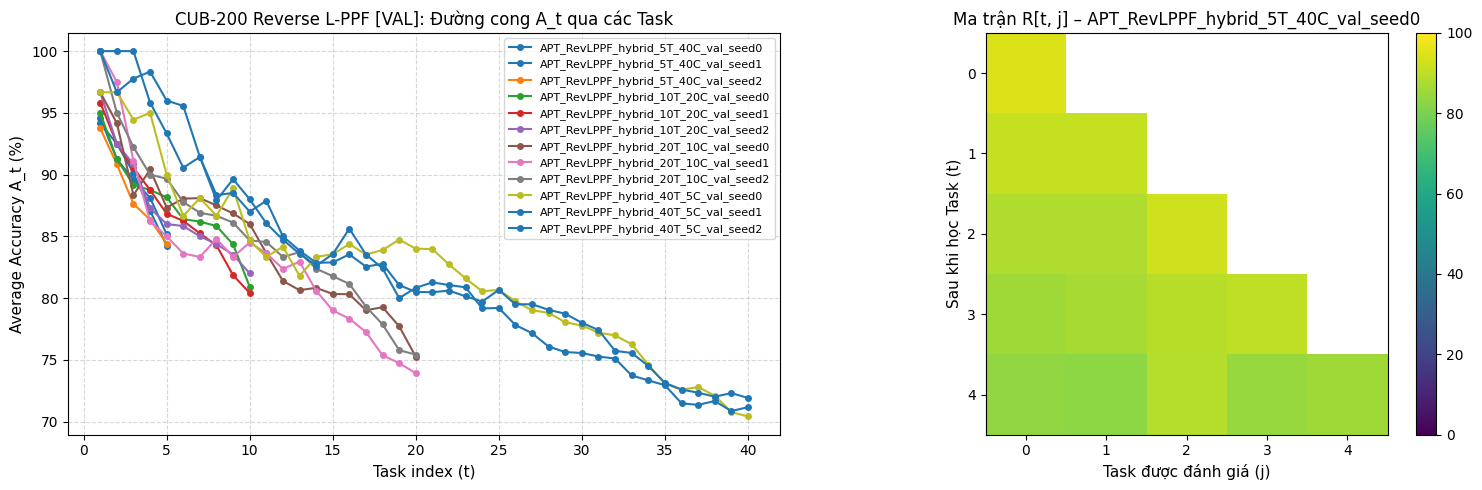

In [8]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Bảng tóm tắt kết quả chi tiết
rows = []
for k, r in RESULTS.items():
    clf = r.get("clf_type", "unknown")
    ppf_m = r.get("ppf_mode", CFG.get("ppf_mode", "layer_wise"))
    method_name = f"APT + Reverse L-PPF ({clf.title()})"
    n_tasks = len(r.get("A_t", []))
    rows.append({
        "Experiment": k,
        "Method": method_name,
        "PPF Mode": ppf_m,
        "Phase": r.get("phase", CFG.get("phase", "val")),
        "Tasks": n_tasks,
        "Seed": r.get("seed", 0),
        "Last Acc (%)": round(r.get("last", 0.0), 2),
        "Avg Acc (%)": round(r.get("avg", 0.0), 2),
        "Forgetting (%)": round(r.get("forgetting", 0.0), 2)
    })

df = pd.DataFrame(rows)
if not df.empty:
    display(df)
    df.to_csv(os.path.join(CFG["out_dir"], "summary_detailed.csv"), index=False)
    
    # 2. Thống kê tổng hợp (Mean +- Std) qua các seed
    summary_stats = df.groupby(["Method", "PPF Mode", "Phase", "Tasks"]).agg({
        "Last Acc (%)": ["mean", "std"],
        "Avg Acc (%)": ["mean", "std"],
        "Forgetting (%)": ["mean", "std"]
    }).round(2)
    print("\n📊 THỐNG KÊ TRUNG BÌNH QUA CÁC SEED:", flush=True)
    display(summary_stats)
    summary_stats.to_csv(os.path.join(CFG["out_dir"], "summary_mean_std.csv"))

# 3. Vẽ đồ thị đường cong A_t và ma trận R[t, j]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Độ chính xác trung bình A_t qua từng Task
colors = plt.cm.tab10(np.linspace(0, 1, max(len(RESULTS), 10)))
for idx, (k, r) in enumerate(RESULTS.items()):
    a_t = r.get("A_t", [])
    if a_t:
        axes[0].plot(range(1, len(a_t) + 1), a_t, marker="o", markersize=4, label=k, color=colors[idx % 10])

axes[0].set_xlabel("Task index (t)", fontsize=11)
axes[0].set_ylabel("Average Accuracy A_t (%)", fontsize=11)
axes[0].set_title(f"CUB-200 Reverse L-PPF [{CFG['phase'].upper()}]: Đường cong A_t qua các Task", fontsize=12)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="best", fontsize=8)

# Subplot 2: Ma trận R[t, j] của kịch bản đầu tiên hoặc seed 0
target_key = next((k for k in RESULTS if "seed0" in k), list(RESULTS.keys())[0] if RESULTS else None)
if target_key and "R" in RESULTS[target_key]:
    target_r = RESULTS[target_key]
    R = np.array(target_r["R"])
    R_masked = np.where(np.tril(np.ones_like(R)) > 0, R, np.nan)
    im = axes[1].imshow(R_masked, vmin=0, vmax=100, cmap="viridis")
    axes[1].set_title(f"Ma trận R[t, j] – {target_key}", fontsize=12)
    axes[1].set_xlabel("Task được đánh giá (j)", fontsize=11)
    axes[1].set_ylabel("Sau khi học Task (t)", fontsize=11)
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(os.path.join(CFG["out_dir"], "evaluation_curves.png"), dpi=150)
plt.show()
